# 01_charts for Hospital Table

In [1]:
## Import plotting libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Set a clean visual style for all charts
sns.set_style('whitegrid')

hospitals = pd.read_csv("../01_Tables_data/hospitals.csv")

## Chart 1: Number of hospitals per Region

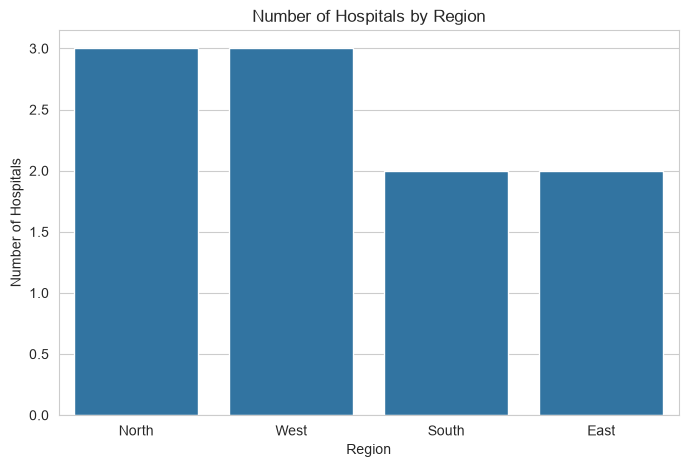

In [2]:



# Create a new blank figure (canvas) to draw the chart on, sized 8 inches wide x 5 inches tall
plt.figure(figsize=(8,5))

## countplot() automatically counts how many rows fall into each category and draws bars for them
sns.countplot(data=hospitals, x='Region', order=hospitals['Region'].value_counts().index)

plt.title('Number of Hospitals by Region')

plt.xlabel('Region')

plt.ylabel('Number of Hospitals')

# plt.savefig('../03_Outputs/hospitals_by_region.png')  ## saves the chart as an image file

plt.show()  ## displays the chart in the notebook

## 2.Bed Capacity by Hospital


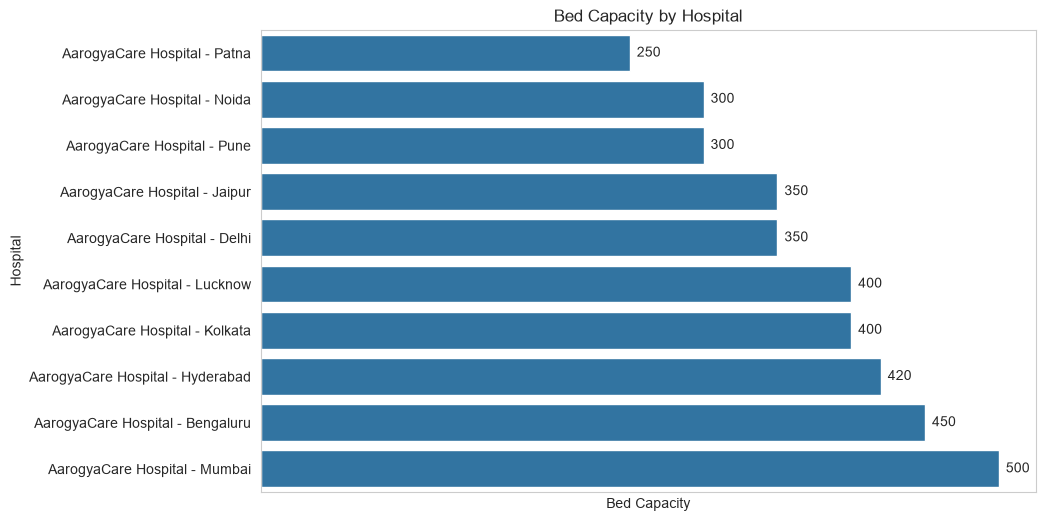

In [3]:

## Sort hospitals from lowest to highest bed capacity, so the chart reads cleanly left-to-right
sorted_hospitals = hospitals.sort_values('Bed_Capacity')

## Create a new blank figure (canvas), 10 inches wide x 6 inches tall
## Wider than the previous charts since hospital names can be long text labels
plt.figure(figsize=(10,6))

## barplot() draws one bar per hospital, with bar length representing Bed_Capacity
## data=sorted_hospitals uses our sorted version so bars appear in ascending order
## x='Bed_Capacity' sets the numeric value that determines each bar's length
## y='Hospital_Name' puts hospital names on the vertical axis (horizontal bars — easier to read long names)
ax=sns.barplot(data=sorted_hospitals, x='Bed_Capacity', y='Hospital_Name')



## Loop through each bar group and place the exact value right next to (in front of) each bar
for container in ax.containers:
    ## padding=5 pushes the number slightly away from the bar's tip so it doesn't overlap
    ax.bar_label(container, padding=5, fontsize=10)

## Remove the x-axis tick numbers/scale entirely, since each bar now shows its own exact value
ax.set_xticks([])

## Remove the x-axis line/label too, since it's no longer needed
ax.set_xlabel('')


## Set the chart's title text
plt.title('Bed Capacity by Hospital')

## Label the x-axis
plt.xlabel('Bed Capacity')

## Label the y-axis
plt.ylabel('Hospital')

## Save this chart as a PNG file into the charts folder
# plt.savefig('../03_Outputs/bed_capacity_by_hospital.png')



## Display the chart inside the notebook
plt.show()





## Let's start Admissions Table — Block 1: Structural Check.

In [4]:
admissions = pd.read_csv("../01_Tables_data/admissions.csv")


## Display the first 5 rows so we can see actual column values in Admissions
admissions.head()

,Admission_ID,Patient_ID,Hospital_ID,Department_ID,Doctor_ID,Admission_Date,Discharge_Date,Admission_Type,Admission_Status,Length_of_Stay
0,ADM00001,P01687,H002,D005,DOC097,2024-02-25,2024-02-28,Day Care,Discharged,3
1,ADM00002,P02371,H008,D002,DOC077,2024-11-29,2024-12-09,Referral,Transferred,10
2,ADM00003,P03850,H005,D004,DOC076,2024-11-11,2024-11-14,Emergency,Referred,3
3,ADM00004,P03603,H004,D006,DOC099,2025-05-12,2025-05-13,Day Care,Discharged,1
4,ADM00005,P03725,H009,D007,DOC059,2025-02-22,2025-02-28,Emergency,Transferred,6


In [5]:
## shape returns (number_of_rows, number_of_columns)
print(admissions.shape)

(6000, 10)


In [6]:
## columns lists all column names exactly as they appear
print(admissions.columns)

Index(['Admission_ID', 'Patient_ID', 'Hospital_ID', 'Department_ID',
       'Doctor_ID', 'Admission_Date', 'Discharge_Date', 'Admission_Type',
       'Admission_Status', 'Length_of_Stay'],
      dtype='str')


In [7]:
## info() shows column names, data types (int/object/float), and non-null counts per column
## this will also tell us if Admission_Date and Discharge_Date loaded as text instead of real dates
admissions.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Admission_ID      6000 non-null   str  
 1   Patient_ID        6000 non-null   str  
 2   Hospital_ID       6000 non-null   str  
 3   Department_ID     6000 non-null   str  
 4   Doctor_ID         6000 non-null   str  
 5   Admission_Date    6000 non-null   str  
 6   Discharge_Date    6000 non-null   str  
 7   Admission_Type    6000 non-null   str  
 8   Admission_Status  6000 non-null   str  
 9   Length_of_Stay    6000 non-null   int64
dtypes: int64(1), str(9)
memory usage: 853.6 KB


## Block 2: Data Quality Check.

In [8]:
## isnull() marks every cell True/False (True = missing); sum() adds them up per column
print(admissions.isnull().sum())

Admission_ID        0
Patient_ID          0
Hospital_ID         0
Department_ID       0
Doctor_ID           0
Admission_Date      0
Discharge_Date      0
Admission_Type      0
Admission_Status    0
Length_of_Stay      0
dtype: int64


In [9]:
## duplicated() flags exact duplicate rows; sum() counts how many exist
print("Duplicate rows:", admissions.duplicated().sum())

Duplicate rows: 0


In [10]:
## Confirm Admission_ID has no duplicate IDs — should equal total row count if clean
print("Unique Admission_IDs:", admissions['Admission_ID'].nunique(), "out of", admissions.shape[0], "rows")

Unique Admission_IDs: 6000 out of 6000 rows


## Now let's convert the two date columns to real datetime format — 

this is essential before we can do any date math (Length_of_Stay validation, trends, etc.).

In [11]:
## Convert Admission_Date from text to actual datetime — errors='coerce' turns any unparseable value into NaT (missing) instead of crashing
admissions['Admission_Date'] = pd.to_datetime(admissions['Admission_Date'], errors='coerce')

## Same conversion for Discharge_Date
admissions['Discharge_Date'] = pd.to_datetime(admissions['Discharge_Date'], errors='coerce')

## Confirm the conversion worked — dtype should now show datetime64 instead of object
admissions.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Admission_ID      6000 non-null   str           
 1   Patient_ID        6000 non-null   str           
 2   Hospital_ID       6000 non-null   str           
 3   Department_ID     6000 non-null   str           
 4   Doctor_ID         6000 non-null   str           
 5   Admission_Date    6000 non-null   datetime64[us]
 6   Discharge_Date    6000 non-null   datetime64[us]
 7   Admission_Type    6000 non-null   str           
 8   Admission_Status  6000 non-null   str           
 9   Length_of_Stay    6000 non-null   int64         
dtypes: datetime64[us](2), int64(1), str(7)
memory usage: 736.4 KB


In [12]:
# ## Check 1: Discharge_Date should NEVER be earlier than Admission_Date
invalid_dates = admissions[admissions['Discharge_Date'] < admissions['Admission_Date']]
print("Admissions with Discharge before Admission:", len(invalid_dates))

Admissions with Discharge before Admission: 0


Does Length_of_Stay match the real date gap?

Your Admissions table has 3 related pieces of information:

Admission_Date (when the patient came in)
Discharge_Date (when the patient left)
Length_of_Stay (a number, supposedly "how many days they stayed")

Logically, Length_of_Stay should just be Discharge_Date minus Admission_Date. So this check does exactly that math ourselves, and compares it to what's already sitting in the Length_of_Stay column — to see if they agree.

In [13]:
## Check 2: Calculate the actual day difference between dates, and compare it to the Length_of_Stay column
## This tells us if Length_of_Stay is a real calculated field or a separately generated random number
admissions['Calculated_LOS'] = (admissions['Discharge_Date'] - admissions['Admission_Date']).dt.days
mismatch = admissions[admissions['Calculated_LOS'] != admissions['Length_of_Stay']]
print("Rows where Length_of_Stay doesn't match calculated days:", len(mismatch))

Rows where Length_of_Stay doesn't match calculated days: 0


Are there any impossible stay lengths?

This one's simpler — it's just a sanity check that no hospital stay is listed as 0 days or negative days, which would be nonsensical in the real world (you can't stay at a hospital for -3 days).

In [14]:
## Check 3: Length_of_Stay sanity check — no admission should have 0 or negative days
print("Admissions with 0 or negative Length_of_Stay:", (admissions['Length_of_Stay'] <= 0).sum())

Admissions with 0 or negative Length_of_Stay: 0


In [15]:
## See how many admissions fall into each Admission_Type category
print(admissions['Admission_Type'].value_counts())
print()

## See how many admissions fall into each Admission_Status category
print(admissions['Admission_Status'].value_counts())

Admission_Type
Emergency    1554
Planned      1500
Referral     1481
Day Care     1465
Name: count, dtype: int64

Admission_Status
Referred       2044
Transferred    1995
Discharged     1961
Name: count, dtype: int64


## Block 3: Numeric Analysis on Length_of_Stay.

In [16]:
## Get count, mean, std deviation, min, quartiles, and max for Length_of_Stay
admissions['Length_of_Stay'].describe()

count    6000.000000
mean        4.320667
std         3.122200
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max        15.000000
Name: Length_of_Stay, dtype: float64

In [17]:
## Calculate IQR (Interquartile Range) — a standard statistical method to detect outliers
Q1 = admissions['Length_of_Stay'].quantile(0.25)
Q3 = admissions['Length_of_Stay'].quantile(0.75)
IQR = Q3 - Q1

## Anything below Q1-1.5*IQR or above Q3+1.5*IQR is considered a statistical outlier
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)


##Lower bound = -4.0 → mathematically, anything below -4 days would be an outlier.
#  But since a hospital stay can't be negative anyway, this bound is meaningless here — just ignore it



## Upper bound = 12.0 → this is the meaningful one.
#  Any admission longer than 12 days is statistically unusual compared to the rest of your data

Lower bound: -4.0
Upper bound: 12.0


## Chart 1: Length of Stay Distribution (Histogram)

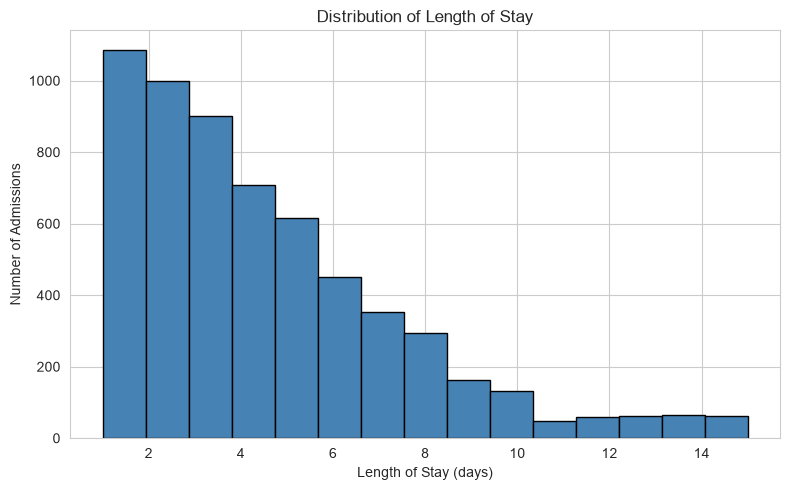

In [18]:
# Import matplotlib for plotting
import matplotlib.pyplot as plt

# Create a new figure with a specific width and height (in inches)
plt.figure(figsize=(8,5))

# Plot a histogram of Length_of_Stay values
# bins=15 means the data range is split into 15 buckets
# color sets the bar color, edgecolor outlines each bar in black
plt.hist(admissions['Length_of_Stay'], bins=15, color='steelblue', edgecolor='black')

# Set the chart title
plt.title('Distribution of Length of Stay')

# Label the x-axis (horizontal)
plt.xlabel('Length of Stay (days)')

# Label the y-axis (vertical)
plt.ylabel('Number of Admissions')

# Automatically adjust spacing so labels don't get cut off
plt.tight_layout()

# Save the chart as a PNG file at 150 dpi (dots per inch = image quality)
# plt.savefig('length_of_stay_distribution.png', dpi=150)

# Display the chart in the notebook
plt.show()

## Chart 2: Admission Type Breakdown (Bar Chart)

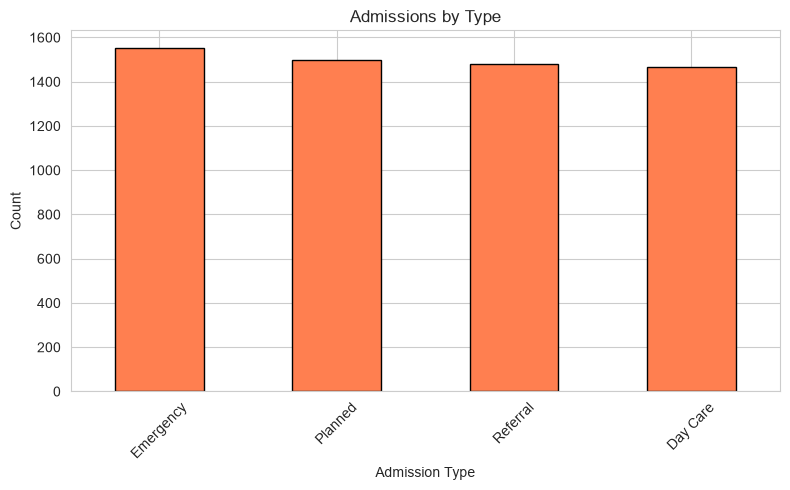

In [19]:
# Create a new figure with a specific size
plt.figure(figsize=(8,5))

# Count how many times each Admission_Type appears, then plot as a bar chart
# kind='bar' makes it a vertical bar chart
admissions['Admission_Type'].value_counts().plot(kind='bar', color='coral', edgecolor='black')

# Set the chart title
plt.title('Admissions by Type')

# Label the x-axis
plt.xlabel('Admission Type')

# Label the y-axis
plt.ylabel('Count')

# Rotate the x-axis labels by 45 degrees so long category names don't overlap
plt.xticks(rotation=45)

# Adjust layout so nothing gets cropped
plt.tight_layout()

# Save the chart as an image file
# plt.savefig('admissions_by_type.png', dpi=150)

# Show the chart
plt.show()

## Chart-3 Admission Status (Pie Chart)

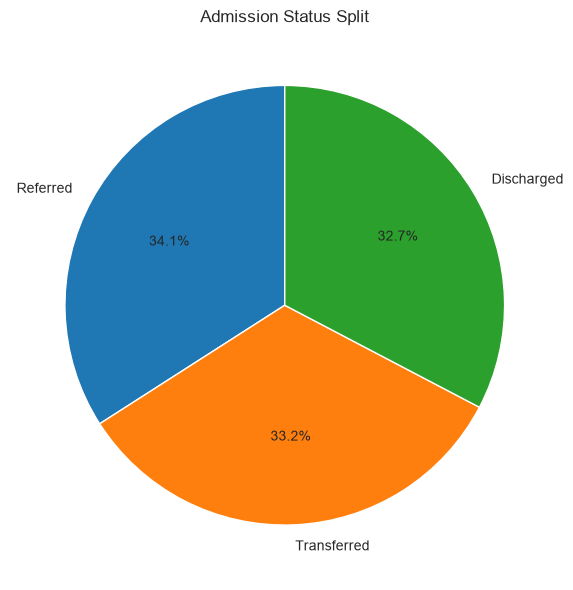

In [20]:
# Create a square figure since pie charts look best that way
plt.figure(figsize=(6,6))

# Count each Admission_Status category, then plot as a pie chart
# autopct shows the percentage on each slice, formatted to 1 decimal place
# startangle rotates the starting point of the first slice
admissions['Admission_Status'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)

# Set the chart title
plt.title('Admission Status Split')

# Remove the default y-axis label (pandas adds one automatically for pie charts)
plt.ylabel('')

# Adjust layout
plt.tight_layout()

# Save the chart
# plt.savefig('admission_status_split.png', dpi=150)

# Show the chart
plt.show()

## Chart-4 Length of Stay by Admission

C:\Users\HP\AppData\Local\Temp\ipykernel_23472\2406368918.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=admissions, x='Admission_Type', y='Length_of_Stay', palette='Set2')


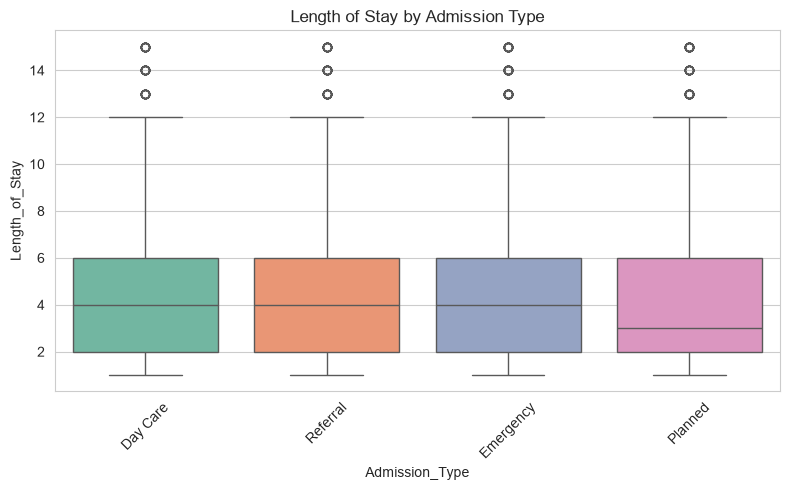

In [21]:
# Import seaborn, a library built on matplotlib for nicer statistical charts
import seaborn as sns

# Create a new figure
plt.figure(figsize=(8,5))

# Draw a boxplot: x-axis is the category (Admission_Type)
# y-axis is the numeric value (Length_of_Stay)
# palette sets the color scheme for the boxes
sns.boxplot(data=admissions, x='Admission_Type', y='Length_of_Stay', palette='Set2')

# Set the chart title
plt.title('Length of Stay by Admission Type')

# Rotate x-axis labels so they don't overlap
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

# Save the chart
# plt.savefig('los_by_admission_type.png', dpi=150)

# Show the chart
plt.show()





##small circles above the whiskers (around 12) → these are outliers

## Confirm Admissions data links correctly to Patients (just one check is enough to demonstrate this)

In [27]:
## Confirm Admissions data links correctly to Patients (just one check is enough to demonstrate this)
# orphan_patients = admissions[~admissions['Patient_ID'].isin(patients['Patient_ID'])]
# print("Admissions with invalid Patient_ID:", len(orphan_patients))

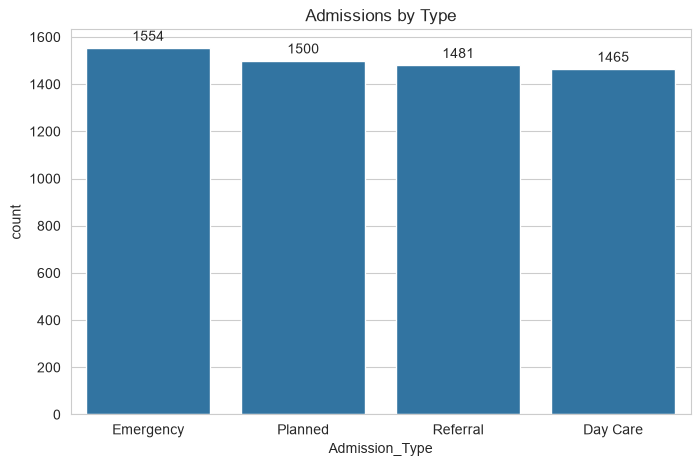

In [25]:
## Chart: Admission_Type distribution
plt.figure(figsize=(8,5))
ax = sns.countplot(data=admissions, x='Admission_Type', order=admissions['Admission_Type'].value_counts().index)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title('Admissions by Type')
# plt.savefig('../03_Outputs/01_charts/admissions_by_type.png')
plt.show()

In [28]:
# ## Does Length_of_Stay correlate with Treatment_Cost? Merge Admissions + Treatments and check
# merged = admissions.merge(treatments, on='Admission_ID')
# correlation = merged['Length_of_Stay'].corr(merged['Treatment_Cost'])
# print("Correlation between Length of Stay and Treatment Cost:", correlation)